# 80 km/h, retour aux 90 km/h : quel effet sur la mortalité routière ?

**Projet Python pour la data science — ENSAE 2A, 2026-2027**
Héloïse Gonon, Samir …, Brice … *(à compléter)*

> **À rédiger en dernier : résumé en 5 lignes** (question, données, méthode, résultat principal, principale limite).

## Comment exécuter ce notebook

1. Installer les dépendances : `pip install -r requirements.txt`.
2. Lancer toutes les cellules dans l'ordre (« Run All »).

Au premier lancement, les données sont téléchargées depuis leurs sources publiques (data.gouv.fr, INSEE, SDES, cartiflette) puis nettoyées : compter **XX minutes** *(à mesurer)*. Les fichiers produits sont gardés dans `data/processed/` (non versionné) et relus aux lancements suivants. Le code est dans `scripts/` ; ce notebook ne fait qu'appeler les fonctions et commenter les résultats.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path("scripts").resolve()))

import data_analysis as da
import graphiques as gr
import indicateurs as ind
from collecte import charger_contours, charger_departements_90, charger_population, charger_radars

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
gr.appliquer_style()

# Variable principale pour Q2 : tués sur les routes départementales hors agglomération
VARIABLE_Q2 = "tues_rd"

## 1. Introduction

### 1.1 Contexte

Le 1er juillet 2018, la vitesse maximale autorisée est passée de 90 à 80 km/h sur les routes à double sens sans séparateur central, hors agglomération. Annoncée en janvier 2018, la mesure a été très contestée. La loi d'orientation des mobilités (LOM) de décembre 2019 a ensuite permis aux départements de relever la limite à 90 km/h sur tout ou partie de leurs routes, après une étude d'accidentalité et l'avis de la commission départementale de sécurité routière. Les premiers relèvements datent de février 2020 (Corrèze et Cantal) ; d'après la table que nous avons construite, 50 départements métropolitains l'avaient fait à la fin 2024, à des dates et sur des linéaires très différents.

C'est une **expérience naturelle** : à partir de 2020, des départements appliquent deux limites différentes, ce qui permet de comparer l'évolution de la mortalité des départements relevés à celle des départements restés à 80 km/h.

Le mécanisme attendu vient du « modèle de puissance » de Nilsson, repris par l'ONISR et le Cerema : le nombre de tués augmente bien plus que proportionnellement avec la vitesse moyenne. Quelques km/h de moins peuvent donc faire baisser sensiblement la mortalité, surtout pour les chocs frontaux et les sorties de route, accidents typiques du réseau secondaire. L'ONISR a publié en février 2024 une évaluation du relèvement sur 2019-2022 ; nous comparons ses résultats aux nôtres en section 5.1.

### 1.2 Question et hypothèses

**La baisse de la vitesse autorisée à 80 km/h a-t-elle réduit la mortalité routière, et le retour aux 90 km/h l'a-t-il fait remonter ?**

| Hypothèse | Ce qu'on devrait observer si elle est vraie |
|---|---|
| H1 : le 80 km/h a réduit la mortalité | Rupture à la baisse en 2018-2019 sur le réseau concerné, absente ou plus faible ailleurs |
| H2 : le retour aux 90 km/h a augmenté la mortalité | Après relèvement, évolution moins favorable dans les départements relevés que dans ceux restés à 80 |
| H3 : l'effet dépend de l'intensité | Écart plus grand pour les relèvements totaux que partiels |
| H4 : l'effet passe par certains types d'accidents | Variation concentrée sur les chocs frontaux et les sorties de route |

> ⚠️ Nous mesurons l'effet d'un **changement de règle**, pas d'un changement de vitesse observée : les vitesses pratiquées ne sont pas disponibles.

## 2. Données

### 2.1 Sources

| Source | Producteur | Accès dans le code | Rôle |
|---|---|---|---|
| Accidents corporels (BAAC) 2010-2024 | ONISR | API data.gouv.fr (`collecte.telecharger_baac`) | Tués, accidents |
| Départements revenus aux 90 km/h | **Construite par nous** | `data/departements_90.csv` (versionné) | Groupes traités / témoins |
| Population par département | INSEE | API Melodi (`charger_population`) | Taux par habitant |
| Ventes de carburants routiers | SDES | API DiDo (`charger_carburants`) | Indicateur du trafic (2020) |
| Radars fixes | Ministère de l'Intérieur | data.gouv.fr (`charger_radars`) | Q3 (annexe) |
| Contours des départements | IGN | `cartiflette` | Cartes |

In [2]:
accidents, panel = ind.charger_ou_construire()
groupes = ind.affecter_groupes(charger_departements_90())
population = charger_population()
contours = charger_contours()

print(f"{len(accidents):,} accidents de {accidents['annee'].min()} à {accidents['annee'].max()}")
print(f"Panel : {panel['code_dep'].nunique()} départements × {panel['date_mois'].nunique()} mois")

2010 : 69379 accidents | 4172 tués
2011 : 66974 accidents | 4111 tués
2012 : 62250 accidents | 3842 tués
2013 : 58397 accidents | 3427 tués
2014 : 59854 accidents | 3557 tués
2015 : 58654 accidents | 3616 tués
2016 : 59432 accidents | 3655 tués
2017 : 60701 accidents | 3600 tués
2018 : 57783 accidents | 3392 tués
2019 : 58840 accidents | 3498 tués
2020 : 47744 accidents | 2780 tués
2021 : 56518 accidents | 3219 tués
2022 : 55302 accidents | 3550 tués
2023 : 54822 accidents | 3398 tués
2024 : 54402 accidents | 3432 tués
881,052 accidents de 2010 à 2024
Panel : 96 départements × 180 mois


### 2.2 La table des départements revenus aux 90 km/h

Aucune table officielle ne recense proprement les relèvements : nous l'avons construite à partir de l'étude ONISR de février 2024 (base officielle), de la liste L'Argus 2026, de la liste de la Ligue de défense des conducteurs et de la presse locale. La méthode complète et les points encore incertains sont dans `docs/collecte_departements.md`.

**Groupes utilisés.** `G90_total` : au moins 80 % du réseau départemental relevé ; `G90_partiel` : relèvement partiel ; `G80` : aucun relèvement avant fin 2024 (Morbihan et Eure, relevés en 2025-2026, sont donc dans `G80`).

In [3]:
display(groupes["groupe"].value_counts().rename("départements").to_frame())
display(
    groupes.loc[groupes["groupe"] != "G80", ["nom_dep", "groupe", "date_releve_eff", "precision_date", "part_releve"]]
    .sort_values("date_releve_eff")
    .head(10)
)

,départements
groupe,
G80,46
G90_partiel,42
G90_total,8


,nom_dep,groupe,date_releve_eff,precision_date,part_releve
52,Haute-Marne,G90_partiel,2020-01-09,jour,0.197
18,Corrèze,G90_total,2020-02-01,jour,0.989
14,Cantal,G90_total,2020-02-01,jour,1.000
19,Côte-d'Or,G90_partiel,2020-03-02,jour,0.204
67,Bas-Rhin,G90_partiel,2020-03-08,jour,0.016
77,Seine-et-Marne,G90_partiel,2020-03-09,jour,0.260
41,Loir-et-Cher,G90_partiel,2020-06-02,jour,0.096
61,Orne,G90_partiel,2020-06-12,jour,0.349
4,Hautes-Alpes,G90_partiel,2020-06-15,jour,0.160
43,Haute-Loire,G90_partiel,2020-06-30,jour,0.032


**Répartition.** Sur les 96 départements métropolitains, 46 sont dans `G80`, 42 dans `G90_partiel` et 8 dans `G90_total` (Allier, Ardèche, Aveyron, Cantal, Corrèze, Creuse, Lozère, Puy-de-Dôme). `G80` comprend Paris, qui n'a aucune route éligible, ainsi que le Morbihan et l'Eure, relevés après la période d'étude.

**Calendrier.** Les relèvements sont précoces : aucun avant 2020, puis 28 en 2020, 11 en 2021, 6 en 2022 et 5 en 2023, soit 90 % entre 2020 et 2022 (médiane : fin octobre 2020). Dix seulement ont eu lieu avant l'été 2020 et 3 pendant le confinement strict (mars à mai 2020) : les premiers relèvements coïncident donc avec la chute du trafic due au Covid, ce qui rend 2020 difficile à lire.

**Intensité.** `G90_partiel` est faiblement traité : la part médiane du réseau relevé est de 8 %, 28 départements sur 42 sont sous 10 % et 6 seulement dépassent 20 % (maximum : 35 %). Le seuil de 80 % est en revanche sans ambiguïté : aucun département relevé n'est entre 35 % et 91 %. `G90_total` ne compte que 8 départements, dont 6 de montagne (typologie Cerema z1) : l'écart avec `G80` peut refléter la géographie autant que la vitesse.

**Incertitudes restantes** (détail dans `docs/collecte_departements.md`) :

- **Dates.** 47 des 50 dates sont connues au jour, 2 au mois et 1 est approximative (Tarn-et-Garonne, février 2023). Une erreur d'un mois est négligeable devant des fenêtres de 24 mois, mais la plupart des dates ne reposent que sur l'ONISR : une seconde source reste à trouver.
- **Annulations en justice.** Au moins cinq départements (Corrèze, Orne, Hautes-Alpes, Hérault, Sarthe) ont vu des arrêtés annulés par un tribunal administratif en 2022 et 2023 (et une nouvelle annulation en 2026 pour l'Hérault), mais restent comptés comme relevés. Nous ne savons pas s'ils sont revenus à 80 km/h ou ont pris de nouveaux arrêtés. La Corrèze, annulée avec effet au 1er janvier 2024, est le cas le plus sensible : c'est un département `G90_total`.
- **Linéaires.** L'ONISR (2022) et L'Argus (2026) divergent pour plusieurs départements (Sarthe : 930 km contre 610 ; Vienne : 429 contre 200 ; Yonne : 450 contre 1 511). Ces trois départements sont dans `G90_partiel`, loin du seuil de 80 % : leur classement ne change pas, mais leur intensité de traitement est incertaine.

**Effet probable sur les résultats.** Compter comme relevé un département redescendu à 80 km/h revient à mélanger traités et non traités : cela devrait **atténuer** l'écart mesuré entre `G90` et `G80`, pas le créer. Comme `G90_partiel` est très peu traité, un effet faible ou nul dans ce groupe serait peu informatif. Les conclusions les plus solides concernent donc `G90_total`, avec la réserve du petit effectif et de la géographie.

### 2.3 Nettoyage et harmonisation des BAAC

Traitements codés dans `scripts/clean_data.py` :

- **séparateur et encodage** détectés pour chaque fichier (ils changent selon les années) ;
- **codes département** des anciens fichiers ramenés au format officiel (`590` → `59`, `201` → `2A`) ;
- **coordonnées** d'avant 2019 converties (entiers divisés par 100 000) et valeurs aberrantes retirées ;
- **valeurs « non renseigné »** (`-1`) converties en valeurs manquantes ;
- usagers et véhicules **agrégés au niveau de l'accident**, puis fusion des quatre tables.

**Réseau concerné par le 80 km/h** : routes nationales ou départementales, hors agglomération, à double sens. Pour Q2, on se restreint aux **routes départementales** (`catr == 3`), les seules que les départements peuvent relever. Indicateur principal : les **tués à 30 jours** (les blessés hospitalisés ne sont plus fiables depuis 2018).

**Usagers en fuite.** Depuis 2021, les BAAC recensent aussi les usagers en fuite, impliqués dans un accident mais non identifiés. Nous ne les retirons pas : un usager en fuite a quitté les lieux et ne peut donc pas figurer parmi les tués. Notre indicateur principal, le nombre de tués, n'est pas concerné.

,accidents,tues,part_reseau_concerne,part_reseau_inconnu,part_vma_80_90
annee,,,,,
2010,67288,3992,0.164,0.001,NaN
2011,65024,3963,0.162,0.002,NaN
2012,60437,3653,0.156,0.004,NaN
2013,56812,3268,0.157,0.001,NaN
2014,58191,3384,0.158,0.001,NaN
2015,56603,3461,0.164,0.002,NaN
2016,57522,3477,0.170,0.002,NaN
2017,58613,3448,0.189,0.006,NaN
2018,55766,3248,0.180,0.007,NaN


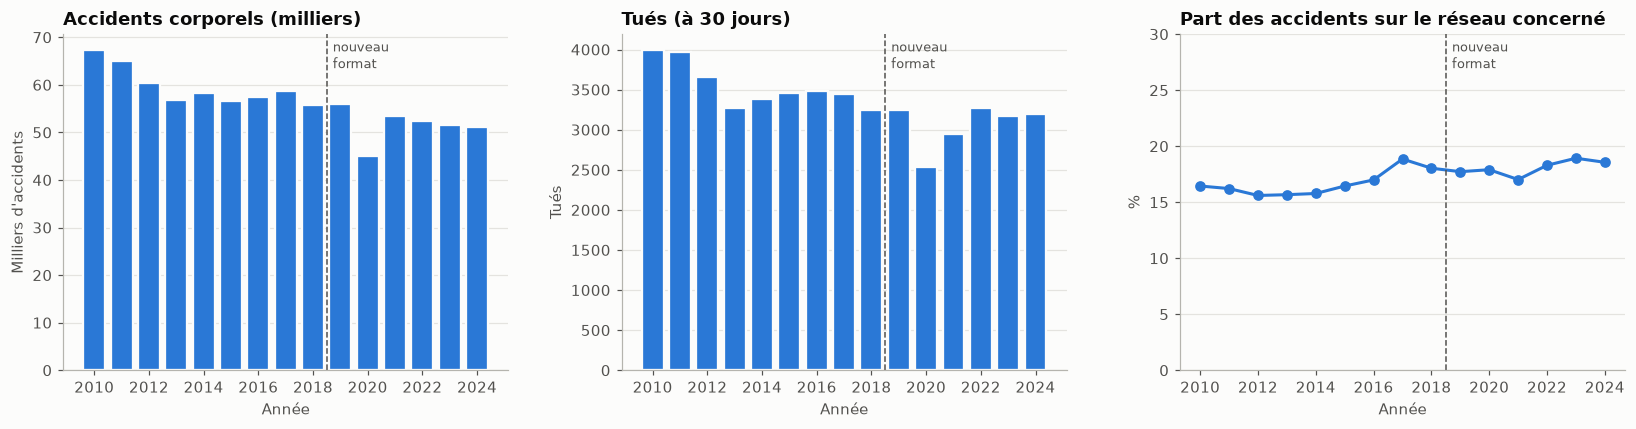

In [4]:
controle = ind.tableau_controle_annuel(accidents)
display(controle.round(3))
gr.tracer_description_annuelle(controle);

**Contrôle du nettoyage.** De 2017 à 2024, le nombre de tués que nous obtenons en métropole est identique, année par année, à celui publié par l'ONISR (par exemple 3 244 en 2019 et 3 193 en 2024). Ce contrôle nous a permis de détecter une erreur : dans le fichier BAAC de 2019, les départements 01 à 09 sont codés sans zéro (« 1 » au lieu de « 01 ») et étaient donc exclus de la métropole, soit 247 tués manquants. Nous avons corrigé le nettoyage.

Malgré le changement de format des BAAC en 2019, les séries d'accidents et de tués ne présentent pas de rupture : la seule cassure est la chute de 2020, liée à la baisse du trafic pendant la crise sanitaire. La part des accidents survenus sur le réseau concerné par le 80 km/h reste comprise entre 15,6 % et 18,9 % sur toute la période, sans saut en 2019 (18,0 % en 2018, 17,7 % en 2019).

**Validité de notre définition du réseau concerné.** Depuis 2019, les BAAC indiquent la vitesse maximale autorisée (VMA), ce qui permet de contrôler notre règle (route nationale ou départementale, hors agglomération, à double sens). Parmi les accidents qu'elle classe sur le réseau concerné, environ 81 % ont effectivement lieu sur une route limitée à 80 ou 90 km/h. Les autres se produisent probablement sur des sections limitées à 70 km/h ou sur des routes à 110 km/h. Notre définition est donc une approximation. Mais cette proportion est très stable de 2019 à 2024 (entre 80,5 % et 81,8 %) : l'erreur de classement ne varie pas dans le temps et ne devrait donc pas biaiser les comparaisons d'évolutions, qui sont l'objet de notre analyse. Ce contrôle est impossible avant 2019, faute de VMA dans les données.

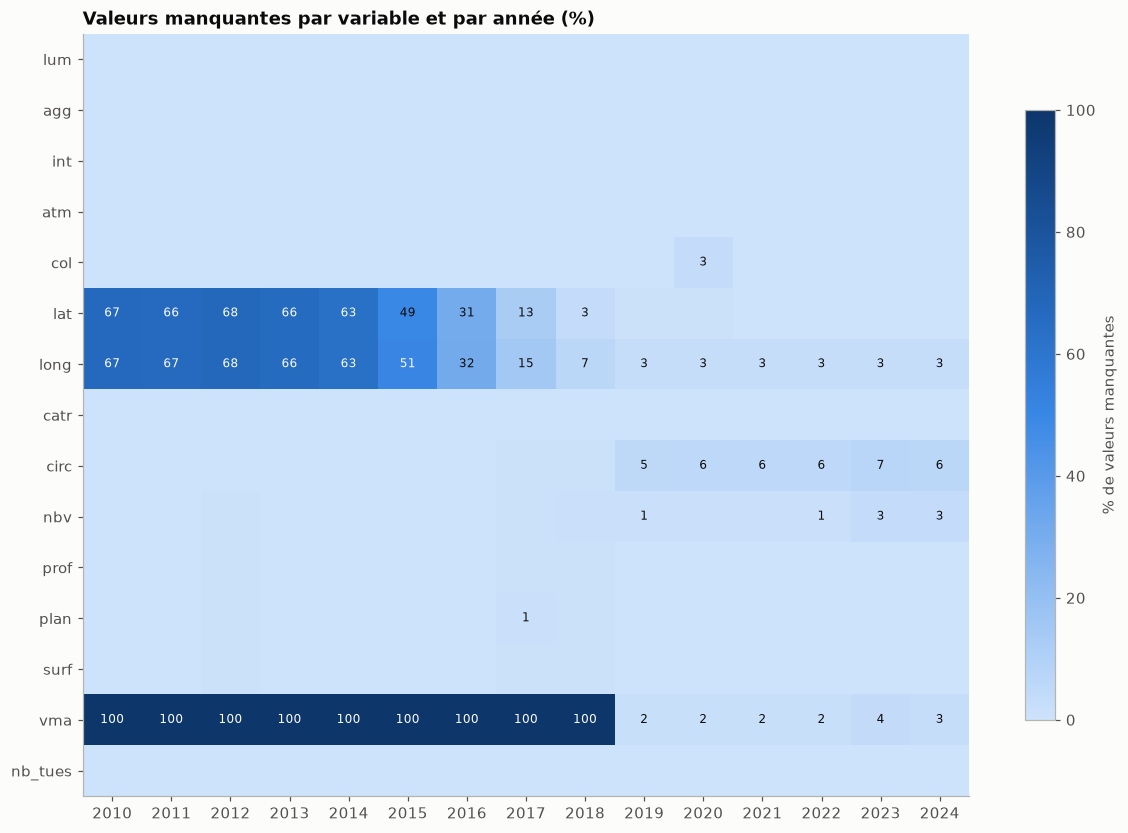

In [5]:
gr.heatmap_manquants(ind.valeurs_manquantes(accidents));

In [6]:
accidents.loc[accidents["long"].isna() & (accidents["annee"] >= 2019), "dep"].value_counts().head()

dep
974    4873
988    1598
976    1073
987     977
978     190
Name: count, dtype: int64

**Valeurs manquantes.** La catégorie de route (`catr`) et la localisation en ou hors agglomération (`agg`), qui servent à définir le réseau concerné, sont presque toujours renseignées. Les coordonnées GPS (`lat`, `long`) manquent pour 63 à 68 % des accidents jusqu'en 2014, puis de moins en moins : elles étaient rarement saisies dans l'ancien format. Comme notre analyse se fait au niveau du département, ce manque est sans conséquence. La VMA n'existe qu'à partir de 2019 (100 % de valeurs manquantes avant, 2 à 4 % ensuite). Le type de collision (`col`) manque pour 3 % des accidents en 2020 seulement, une année exclue de l'analyse par type de collision (section 4.4).

Le point le plus important concerne le régime de circulation (`circ`), qui indique si une route est à double sens : presque toujours renseigné avant 2019, il manque pour 5 à 7 % des accidents à partir de 2019. C'est ce qui fait passer la part des accidents dont le réseau est inconnu de moins de 1 % à plus de 5 % (tableau ci-dessus). La cellule suivante mesure l'effet de cette rupture sur notre réseau.

Depuis 2019, la longitude manque encore pour environ 3 % des accidents : ce sont des accidents d’outre-mer, dont la longitude sort des bornes de notre filtre, sans effet sur une analyse limitée à la métropole.

In [7]:
hors_agg_rn_rd = accidents[accidents["agg"].eq(1) & accidents["catr"].isin([2, 3])]
hors_agg_rn_rd["circ"].isna().groupby(hors_agg_rn_rd["annee"]).mean().round(3)

annee
2010    0.001
2011    0.001
2012    0.001
2013    0.001
2014    0.001
2015    0.001
2016    0.002
2017    0.006
2018    0.007
2019    0.023
2020    0.028
2021    0.029
2022    0.030
2023    0.036
2024    0.035
Name: circ, dtype: float64

Sur les routes nationales et départementales hors agglomération, la part d'accidents dont le régime de circulation est inconnu passe de moins de 1 % jusqu'en 2018 à 2,3 % en 2019, puis à environ 3,5 % en 2023-2024. Cette rupture vient très probablement du changement de format de 2019, qui code explicitement les valeurs non renseignées. Ces accidents ne sont classés dans aucun périmètre : les comptages du réseau concerné sont donc légèrement sous-estimés à partir de 2019, et pas avant.

**Conséquence pour Q1** : une partie de la baisse observée après le passage à 80 km/h, de l'ordre de 2 à 3 %, pourrait venir de ce changement de codage et non de la réforme. **Pour Q2**, l'effet est beaucoup plus faible : départements relevés et départements restés à 80 km/h sont comparés sur les mêmes années, toutes postérieures à 2019, et la sous-estimation les touche de la même façon, sauf si la qualité de saisie diffère d'un département à l'autre.

In [8]:
display(da.verifier_panel(panel))

departements                     96
mois                            180
lignes                        17280
departements_sans_groupe          0
dep_annees_sans_population        0
dep_annees_sans_carburants        0
dtype: int64

Le panel compte 96 départements métropolitains et 180 mois (janvier 2010 à décembre 2024), soit 17 280 lignes, sans doublon. Chaque département est affecté à un groupe et dispose, pour chaque année, d'une population et de ventes de carburants.

In [9]:
comparaison = ind.verifier_coherence_onisr(accidents, charger_departements_90())
display(comparaison[["tues_2019_calc", "tues_ha_2019_onisr", "tues_2022_calc", "tues_ha_2022_onisr"]].sum().to_frame("total"))

,total
tues_2019_calc,1944.0
tues_ha_2019_onisr,1944.0
tues_2022_calc,1934.0
tues_ha_2022_onisr,1934.0


Pour 2019 et 2022, nous retrouvons exactement les tués hors agglomération et hors autoroute publiés par l'ONISR dans son étude sur le relèvement à 90 km/h : 1 944 en 2019 et 1 934 en 2022, en sommant les départements. Notre périmètre géographique et notre comptage des tués reproduisent donc la source officielle. C'est ce contrôle qui a révélé l'erreur sur les codes départementaux de 2019 : avant correction, il manquait 154 tués en 2019, soit exactement la somme des départements 01 à 09.

## 3. Le passage à 80 km/h en 2018 (Q1, H1)

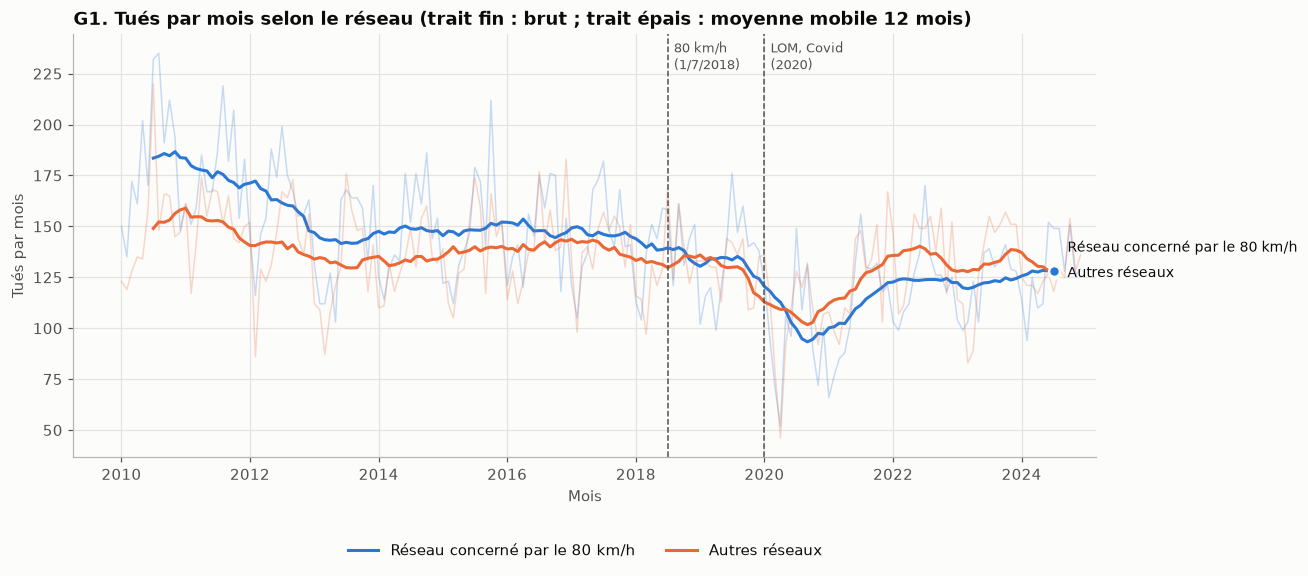

In [21]:
gr.tracer_mensuel_reseau(ind.tues_mensuels_par_reseau(accidents));

In [22]:
bilan = da.bilan_national(panel)
display(bilan[["tues_80", "tues_temoin", "indice_tues_80", "indice_tues_temoin", "indice_carburants_routiers_m3"]].round(1))

,tues_80,tues_temoin,indice_tues_80,indice_tues_temoin,indice_carburants_routiers_m3
annee,,,,,
2010,2202,1788,124.5,106.3,98.0
2011,2122,1835,120.0,109.1,96.7
2012,1938,1708,109.6,101.5,95.8
2013,1706,1557,96.5,92.6,94.9
2014,1786,1593,101.0,94.7,95.7
2015,1778,1680,100.5,99.9,96.7
2016,1775,1690,100.4,100.5,101.1
2017,1753,1677,99.1,99.7,102.2
2018,1674,1557,94.6,92.6,100.9


**Lecture de G1.** Le graphique compare les tués par mois sur le réseau concerné (routes nationales et départementales à double sens, hors agglomération) et sur tous les autres réseaux (agglomération, autoroutes, routes à chaussées séparées, voies communales). La moyenne mobile est centrée : le point d'un mois résume les six mois qui précèdent et les six qui suivent. La courbe épaisse intègre donc des mois postérieurs à la réforme dès janvier 2018, et il faut lire la rupture sur les traits fins ou sur les totaux annuels ci-dessus. Trois phases se dégagent :

- **de 2010 à 2013**, la mortalité baisse fortement sur le réseau concerné (de 2 202 à 1 706 tués par an, −23 %), et nettement moins sur les autres réseaux (−13 %) ;
- **de 2013 à 2017**, les deux séries sont presque plates, autour de 145 à 150 tués par mois sur le réseau concerné et de 130 à 145 sur les autres ;
- **autour de la réforme**, les deux courbes baissent ensemble, puis se rejoignent en 2019 autour de 130 tués par mois.

La chute de 2020 (confinements) est la seule rupture nette de toute la période.

**Bilan national.** Par rapport à la moyenne 2015-2017, les tués sur le réseau concerné baissent de 5,4 % en 2018, une année à moitié à 80 km/h, puis de 9,4 % en 2019, première année complète à 80 km/h (1 602 tués). Sur les autres réseaux, la baisse est de 7,4 % en 2018 et de 7,3 % en 2019. En 2019, le réseau concerné ne fait donc mieux que les autres que d'environ 2 points, ou 4 points avec la référence 2013-2017 utilisée par le Cerema. Le trafic n'explique pas ces baisses : les ventes de carburants sont stables de 2017 à 2019 (indices 102,2, 100,9 et 101,9).

**2020 et après.** En 2020, les ventes de carburants reculent de 14 % par rapport à 2019, et les tués de 25 % sur le réseau concerné et de 19 % sur les autres réseaux. La mortalité suit donc la chute du trafic, mais plus fortement. Une explication possible : les carburants, qui incluent les poids lourds, mesurent mal la baisse des trajets de loisir en voiture. Le rebond est ensuite plus lent sur le réseau concerné. En 2022, alors que les ventes de carburants dépassent leur niveau de 2019, les tués y restent 7 % sous 2019, contre 7 % au-dessus sur les autres réseaux. L'écart se referme en 2024 (−4 % et −2 % par rapport à 2019). Au niveau national, le retour aux 90 km/h ne se voit donc pas, ce qui n'a rien d'étonnant : il ne porte que sur une petite partie du réseau (section 2.2). Cette période mêle le Covid, les relèvements et des changements de mobilité : elle ne permet pas d'évaluer le 80 km/h, et le retour aux 90 km/h est étudié département par département en section 4.

**Comparaison avec l'évaluation officielle.** Le Cerema ([rapport final, juillet 2020](https://www.onisr.securite-routiere.gouv.fr/sites/default/files/2020-08/Cerema-EvaluationV80-Juillet2020-V2.pdf)) estime que la mesure a fait baisser de 12 % les tués sur le réseau hors agglomération et hors autoroute par rapport au reste du réseau, soit 349 vies épargnées sur les 20 premiers mois par rapport à la moyenne 2013-2017. Il mesure aussi une baisse de 3,3 km/h des vitesses moyennes pratiquées. Notre écart est nettement plus faible. Les différences de périmètre peuvent y contribuer : le Cerema compte tout le réseau hors agglomération hors autoroute, alors que nous classons les voies communales et les routes à chaussées séparées dans les autres réseaux. La période compte aussi : 20 mois jusqu'en février 2020 pour le Cerema, l'année 2019 pour nous. Notre lecture de G1 rejoint en revanche le bilan à 18 mois de l'ONISR : la mortalité a baissé sur tous les réseaux de fin 2017 à mi-2018, puis surtout hors agglomération après l'été 2018.

**Conclusion sur H1.** Nos données vont dans le sens de H1 sans suffire à la confirmer. À trafic constant, la mortalité sur le réseau concerné baisse de 9 % en 2019 par rapport à 2015-2017, un peu plus que sur les autres réseaux. Trois éléments imposent cependant la prudence :

- **l'écart avec les autres réseaux est faible** (2 à 4 points) et du même ordre que le biais de codage de 2019 mis en évidence en section 2.3 (2 à 3 %), qui fait baisser artificiellement les comptages du réseau concerné ;
- **la baisse commence sur tous les réseaux avant juillet 2018** : une partie relève d'une tendance commune, par exemple les autres mesures du comité interministériel de janvier 2018 ou l'amélioration du parc automobile ;
- **le réseau concerné se rapprochait déjà des autres depuis 2010** : le rapport entre ses tués et ceux des autres réseaux passe de 1,23 en 2010 à 1,05 en 2017. La convergence de 2019 (1,03) prolonge en partie cette tendance.

H1 est donc plausible, mais notre approche descriptive ne retrouve pas l'ampleur de l'effet estimé par le Cerema : nos données sont compatibles avec un effet modéré de la mesure, sans pouvoir le séparer des autres facteurs. Le retour aux 90 km/h (Q2) offre un cadre plus favorable, puisqu'on peut y comparer des départements traités et non traités sur les mêmes mois.

## 4. Le retour aux 90 km/h (Q2)

### 4.1 Qui a relevé, et quand ?

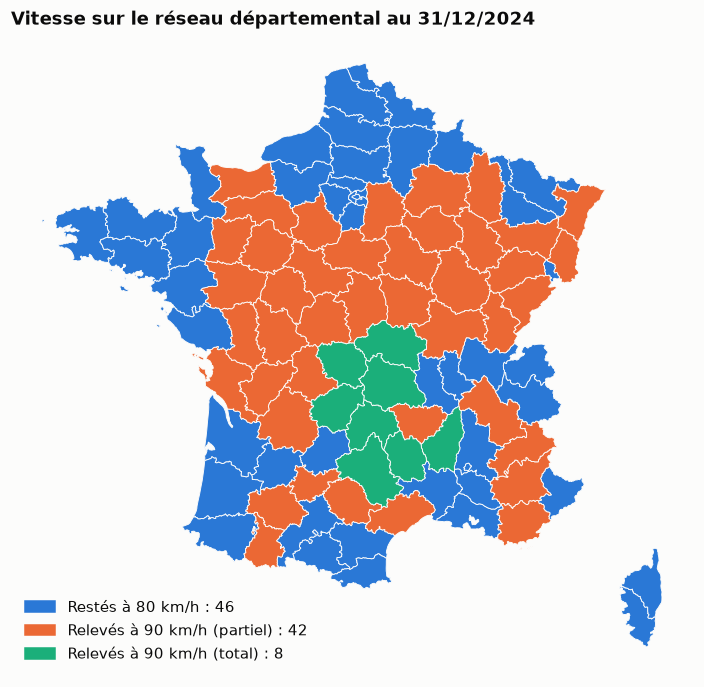

In [12]:
gr.carte_groupes(contours, groupes[["code_dep", "groupe"]]);

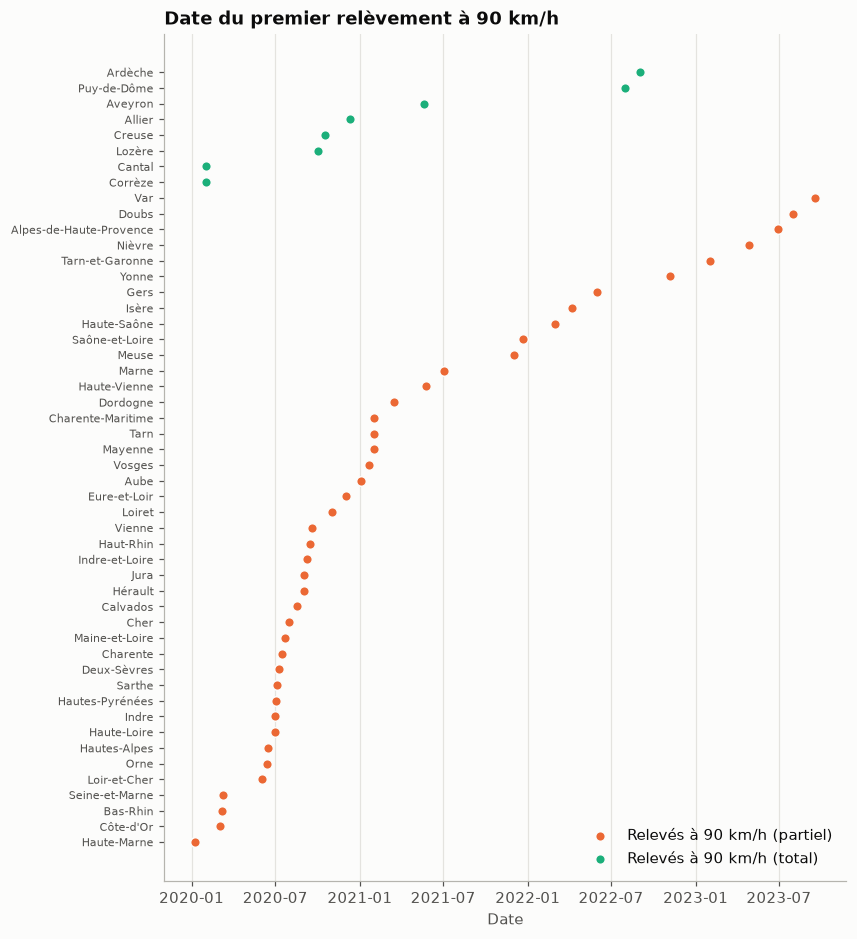

In [13]:
gr.tracer_calendrier(groupes.assign(date_releve=groupes["date_releve_eff"]));

> **À rédiger.** Les départements relevés sont-ils géographiquement concentrés (centre, rural, montagne) ? Que cela implique-t-il pour la comparabilité avec les départements restés à 80 (biais de sélection) ? Les relèvements sont-ils simultanés ou échelonnés ?

### 4.2 Évolution comparée des groupes (graphique central)

Tués sur les routes départementales hors agglomération, par million d'habitants, en indice (moyenne 2015-2017 = 100). La bande colorée est un intervalle à 95 % (approximation de Poisson).

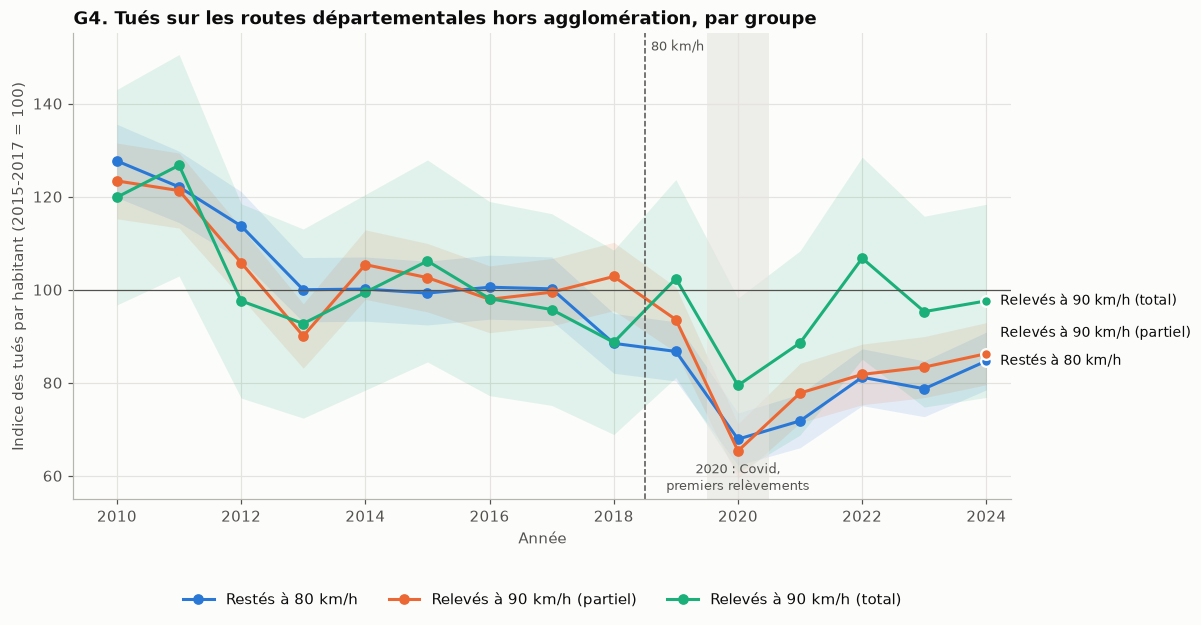

In [14]:
serie_g4 = ind.serie_groupes_ic(panel, variable=VARIABLE_Q2, par_habitant=True)
gr.tracer_series_groupes_ic(
    serie_g4,
    titre="G4. Tués sur les routes départementales hors agglomération, par groupe",
    ylabel="Indice des tués par habitant (2015-2017 = 100)",
);

> **À rédiger.** **Avant 2020**, les courbes sont-elles parallèles (condition de validité de la comparaison) ? **Après 2020**, les départements relevés s'écartent-ils de ceux restés à 80, et dans quel sens ? L'écart est-il plus fort pour le relèvement total (**H3**) ? Les intervalles se chevauchent-ils ?

### 4.3 Étude d'événement : chaque département aligné sur sa propre date

Pour chaque département relevé, l'année 0 est celle de son relèvement. On compare ses tués à ce qu'il aurait connu s'il avait suivi la même évolution que les départements restés à 80 km/h (base : moyenne des années −3 à −1). 100 = même évolution que les G80 ; au-dessus de 100 = évolution moins favorable.

groupe,G90_partiel,G90_total
annee_relative,,
-5,42,8
-4,42,8
-3,42,8
-2,42,8
-1,42,8
0,42,8
1,42,8
2,37,8
3,33,6


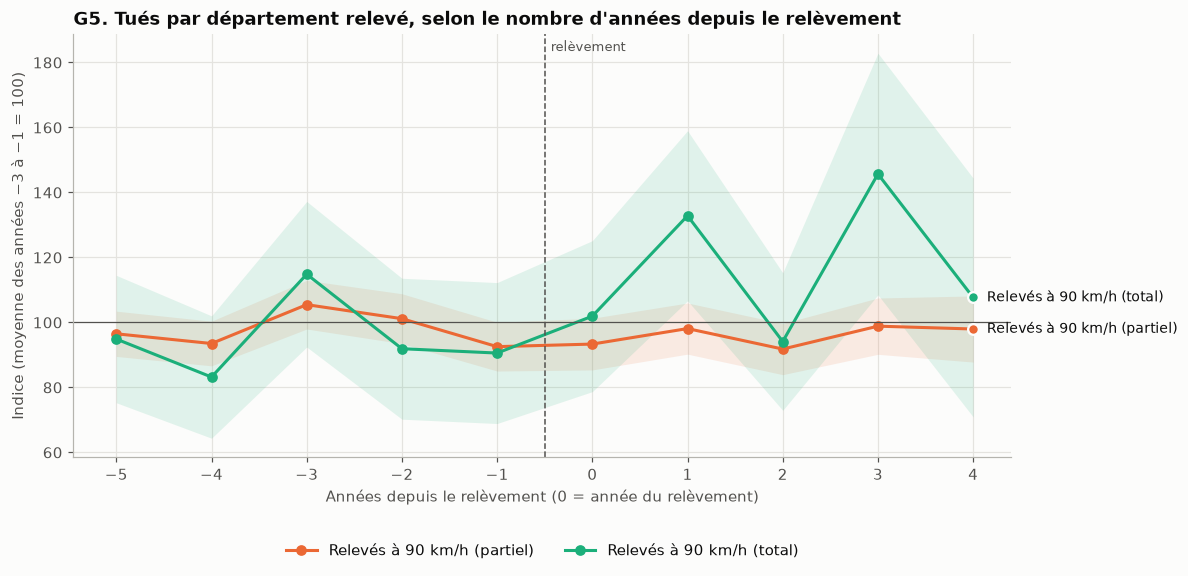

In [15]:
evenement = ind.etude_evenement(panel, variable=VARIABLE_Q2)
gr.tracer_evenement(evenement);
display(evenement.pivot(index="annee_relative", columns="groupe", values="nb_departements"))

> **À rédiger.** L'indice est-il stable autour de 100 avant le relèvement ? Monte-t-il après ? Attention : le nombre de départements diminue pour les dernières années (tableau ci-dessus), ces points sont donc plus fragiles.

### 4.4 Par type d'accident (H4)

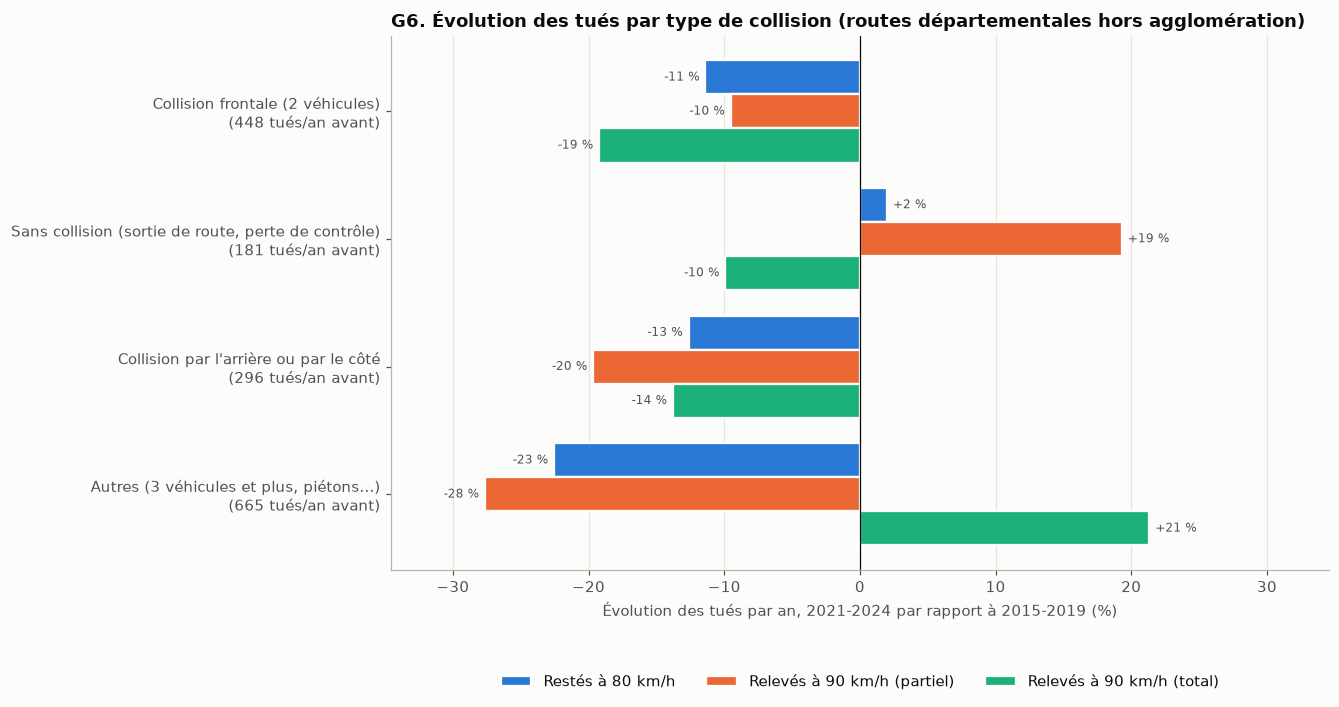

In [16]:
categories = ind.evolution_par_categorie(accidents, groupes, categorie="type_collision")
gr.tracer_evolution_categories(
    categories, "type_collision", ind.LIBELLES_COLLISION,
    titre="G6. Évolution des tués par type de collision (routes départementales hors agglomération)",
);

> **À rédiger.** Les évolutions diffèrent-elles entre groupes surtout pour les collisions frontales et les accidents sans collision (sorties de route) ? Conclure sur **H4**. Rappeler que certains départements relevés en 2022-2023 sont comptés « après » dès 2021.

### 4.5 Cartes avant / après

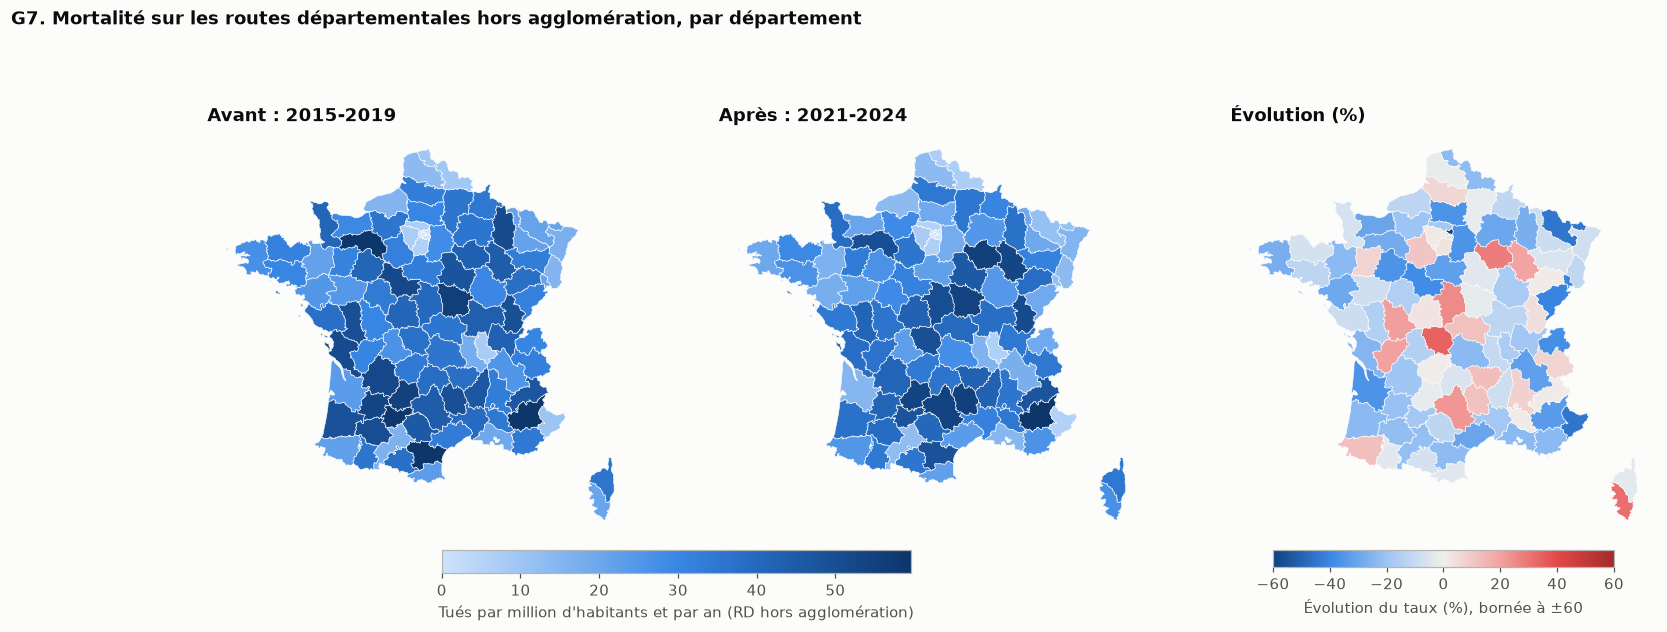

In [17]:
taux = ind.taux_avant_apres_par_dep(accidents, population, perimetre="rd")
gr.cartes_avant_apres(contours, taux);

> **À rédiger.** Où la mortalité par habitant est-elle la plus forte ? Les hausses se concentrent-elles dans les départements relevés (comparer avec la carte des groupes) ? Attention aux petits départements, où quelques décès changent beaucoup le taux.

## 5. Démarche : différence de différences et robustesse

Pour chaque département relevé, on compare les tués sur une fenêtre avant et une fenêtre après son relèvement (même longueur, multiple de 12 mois pour garder la même saisonnalité), et on retire l'évolution des départements restés à 80 km/h **sur les mêmes mois** :

$$\text{effet} = \underbrace{(\text{évolution des départements relevés})}_{\%} - \underbrace{(\text{évolution des G80 sur les mêmes mois})}_{\%}$$

Les mois de confinement strict (mars-mai et novembre 2020) sont exclus.

In [18]:
avant_apres = da.avant_apres_releve(panel, fenetre=24, variable=VARIABLE_Q2)
display(da.synthese_avant_apres(avant_apres))

,nb_departements,avant,apres,g80_avant,g80_apres,temoin_avant,temoin_apres,evol_dep_pct,evol_g80_pct,evol_reseau_temoin_pct,ecart_pts
groupe,,,,,,,,,,,
G90_partiel,42,864,969,42434,43527,864,969,12.2,2.6,12.2,9.6
G90_total,8,113,164,8654,8427,113,164,45.1,-2.6,45.1,47.8


> **À rédiger.** Lire le tableau : de combien les tués ont-ils évolué dans chaque groupe, et chez les G80 sur les mêmes mois ? Quel est l'écart ?

effet_points_%  ic_bas  \
configuration                        groupe_traite                             
Référence                            total                      47.8    13.0   
                                     total + partiel            14.3     4.3   
Sans l'année 2020                    total                      77.0    26.4   
                                     total + partiel            21.2     8.5   
Accidents mortels au lieu des tués   total                      48.3    12.2   
                                     total + partiel            12.2     2.1   
Départements urbains exclus (z6, z7) total                      49.3    14.5   
                                     total + partiel            16.1     6.1   
Dates de relèvement − 6 mois         total                      27.9    -5.2   
                                     total + partiel             2.2    -6.4   
Dates de relèvement + 6 mois         total                      41.4     2.7   
                                     total + partiel            11.0     0.7   
Réseau 80 complet (RN + RD)          total                      44.1    11.7   
                                     total + partiel            14.2     4.8   

                                                      ic_haut  evol_traites_%  \
configuration                        groupe_traite                              
Référence                            total               82.5            45.1   
                                     total + partiel     24.2            16.0   
Sans l'année 2020                    total              127.6            89.0   
                                     total + partiel     34.0            35.4   
Accidents mortels au lieu des tués   total               84.5            46.2   
                                     total + partiel     22.3            14.6   
Départements urbains exclus (z6, z7) total               84.1            45.1   
                                     total + partiel     26.0            16.0   
Dates de relèvement − 6 mois         total               61.0            23.7   
                                     total + partiel     10.8            -8.4   
Dates de relèvement + 6 mois         total               80.2            52.0   
                                     total + partiel     21.3            24.1   
Réseau 80 complet (RN + RD)          total               76.6            41.1   
                                     total + partiel     23.7            15.2   

                                                      evol_g80_%  \
configuration                        groupe_traite                 
Référence                            total                  -2.6   
                                     total + partiel         1.7   
Sans l'année 2020                    total                  12.0   
                                     total + partiel        14.2   
Accidents mortels au lieu des tués   total                  -2.1   
                                     total + partiel         2.4   
Départements urbains exclus (z6, z7) total                  -4.2   
                                     total + partiel        -0.1   
Dates de relèvement − 6 mois         total                  -4.2   
                                     total + partiel       -10.6   
Dates de relèvement + 6 mois         total                  10.6   
                                     total + partiel        13.1   
Réseau 80 complet (RN + RD)          total                  -3.0   
                                     total + partiel         1.0   

                                                      victimes_avant  \
configuration                        groupe_traite                     
Référence                            total                       113   
                                     total + partiel             977   
Sans l'année 2020                    total                        82   
                           

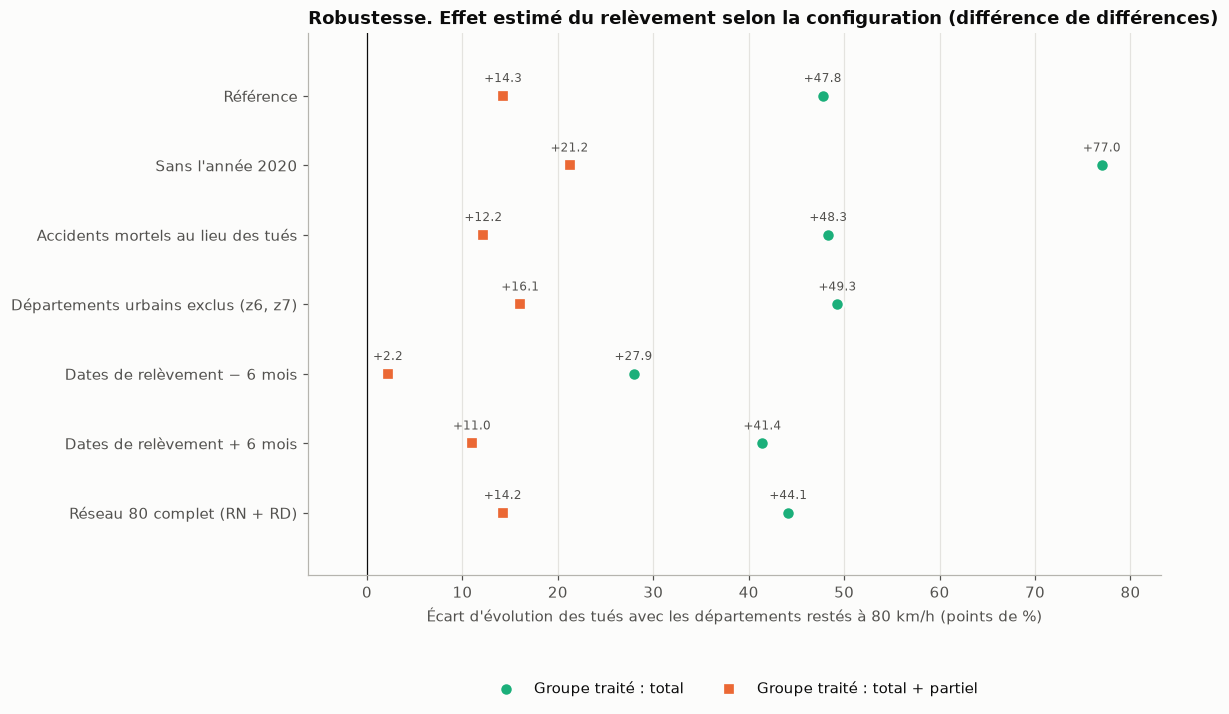

In [19]:
robustesse = ind.tableau_robustesse(panel, variable=VARIABLE_Q2)
display(robustesse.round(1))
gr.tracer_robustesse(robustesse);

> **À rédiger.** Le signe de l'effet est-il le même dans toutes les configurations ? Les intervalles (`ic_bas`, `ic_haut`) contiennent-ils 0 ? Une conclusion qui tient partout est solide ; une conclusion qui ne tient que dans une configuration doit être présentée avec prudence.

### 5.1 Comparaison avec l'évaluation de l'ONISR

En février 2024, l'ONISR a publié une évaluation du relèvement à 90 km/h sur 2019-2022. Sa méthode est simple :

- **Groupes.** *Groupe 90* : 45 départements ayant pris au moins un arrêté de relèvement avant fin 2022 ; *groupe 80* : 51 départements sans arrêté. Les 6 départements qui ont décidé en 2022 comptent dans le groupe 80 avant leur décision et dans le groupe 90 après.
- **Période.** 2019 (dernière année complète à 80 km/h sans exception) contre 2022, sur les mêmes périodes de l'année. 2020 et 2021 sont écartées à cause du Covid.
- **Indicateur et périmètre.** Tués des BAAC hors agglomération et hors autoroute, quel que soit le gestionnaire de la route. Aucune correction par le trafic.
- **Résultat.** Le groupe 90 passe de 763 à 774 tués (+1,4 %) et le groupe 80 de 1 181 à 1 160 (−1,8 %), soit une surmortalité estimée à 83 décès. Elle se concentre dans les départements de montagne (+55 % contre −21 % pour le groupe 80). L'ONISR reste prudent : petits effectifs, une seule année de référence de chaque côté, effets de la pandémie, et il ne peut pas isoler l'effet propre du relèvement.

Notre analyse reprend la même question avec une méthode différente :

| | ONISR | Notre analyse |
|---|---|---|
| **Groupes** | G80 / G90 (45 départements à fin 2022) | `G80` / `G90_partiel` / `G90_total` (50 départements relevés jusqu'à fin 2023 ; Morbihan et Eure dans `G80`) |
| **Période** | 2019 contre 2022 | fenêtres de 12 à 24 mois avant et après la date de relèvement de chaque département |
| **2020-2021** | exclues | incluses, sauf les mois de confinement strict (mars à mai et novembre 2020) |
| **Périmètre** | hors agglomération, hors autoroute, tous gestionnaires | routes départementales hors agglomération à double sens (`tues_rd`) |
| **Comparaison** | groupe 90 contre groupe 80 | différence de différences : évolution du département moins celle des `G80` sur les mêmes mois |
| **Trafic** | aucune correction | aucune correction dans la comparaison principale |

In [20]:
# Tableau 2019 / 2022 de l'ONISR (tués hors agglomération, hors autoroute) avec deux définitions des groupes
onisr = ind.comparaison_onisr(groupes)
display(onisr)

# Départements de montagne (typologie Cerema z1), où l'ONISR concentre la surmortalité
display(ind.comparaison_onisr(groupes, par_typologie=True).xs("z1", level="typologie_cerema"))

departements  tues_2019  \
regroupement                    groupe                                 
ONISR (relevés avant fin 2022)  Groupe 80              51     1096.0   
                                Groupe 90              45      848.0   
Projet (relevés avant fin 2024) G80                    46      969.0   
                                G90_partiel            42      864.0   
                                G90_total               8      111.0   

                                             tues_2022  evolution  \
regroupement                    groupe                              
ONISR (relevés avant fin 2022)  Groupe 80       1114.0       18.0   
                                Groupe 90        820.0      -28.0   
Projet (relevés avant fin 2024) G80             1018.0       49.0   
                                G90_partiel      806.0      -58.0   
                                G90_total        110.0       -1.0   

                                             evolution_pct  
regroupement                    groupe                      
ONISR (relevés avant fin 2022)  Groupe 80              1.6  
                                Groupe 90             -3.3  
Projet (relevés avant fin 2024) G80                    5.1  
                                G90_partiel           -6.7  
                                G90_total             -0.9

departements  tues_2019  \
regroupement                    groupe                                 
ONISR (relevés avant fin 2022)  Groupe 80               4       84.0   
                                Groupe 90               9       86.0   
Projet (relevés avant fin 2024) G80                     3       68.0   
                                G90_partiel             4       41.0   
                                G90_total               6       61.0   

                                             tues_2022  evolution  \
regroupement                    groupe                              
ONISR (relevés avant fin 2022)  Groupe 80         73.0      -11.0   
                                Groupe 90        112.0       26.0   
Projet (relevés avant fin 2024) G80               59.0       -9.0   
                                G90_partiel       53.0       12.0   
                                G90_total         73.0       12.0   

                                             evolution_pct  
regroupement                    groupe                      
ONISR (relevés avant fin 2022)  Groupe 80            -13.1  
                                Groupe 90             30.2  
Projet (relevés avant fin 2024) G80                  -13.2  
                                G90_partiel           29.3  
                                G90_total             19.7

**Le résultat global de l'ONISR tient à quelques départements.** En reprenant ses groupes, mais en comptant chaque département relevé en 2022 pour l'année entière (notre table ne donne que des totaux annuels), on obtient l'inverse de l'étude : les 45 départements relevés passent de 848 à 820 tués (−3,3 %) et les 51 autres de 1 096 à 1 114 (+1,6 %). La différence vient des 6 départements qui ont décidé en 2022 (Ardèche, Gers, Haute-Saône, Isère, Puy-de-Dôme, Yonne) : ils passent de 164 à 106 tués (−35 %). L'ONISR, plus précis que nous sur ce point, les compte dans le groupe 80 avant leur décision et dans le groupe 90 après ; ses totaux sont d'ailleurs cohérents avec ce découpage (85 de leurs 164 tués de 2019 et 46 de leurs 106 tués de 2022 tombent du côté du groupe 80). Sans ces 6 départements, les 39 relevés avant 2022 passent de 684 à 714 tués (+4,4 %), contre +1,6 % pour les 51 autres : on retrouve le sens de l'ONISR. Avec nos trois groupes, le constat 2019-2022 change encore (`G80` +5,1 %, `G90_partiel` −6,7 %, `G90_total` −0,9 %). **L'écart global de l'ONISR (3 points) est donc fragile** : son signe dépend de la façon de classer quelques départements dont la mortalité a beaucoup varié.

**En montagne, les deux analyses concordent.** L'ONISR concentre la surmortalité dans les départements de montagne (+55 % contre −21 %). Dans la typologie Cerema z1, nous trouvons le même sens : +30 % pour les 9 départements relevés avant fin 2022 contre −13 % pour les 4 autres, et +71 % sans les départements relevés en 2022. Ces effectifs sont très petits (4 départements et 84 tués en 2019 côté non relevé).

**Les départements relevés en totalité vont dans le même sens, à une condition.** Sur 2019-2022, `G90_total` semble faire mieux que `G80` (−0,9 % contre +5,1 %). Mais deux de ses 8 départements, l'Ardèche et le Puy-de-Dôme, n'ont relevé qu'en août-septembre 2022 : leur année 2022 est surtout antérieure au relèvement. Sans eux, les 6 autres passent de 48 à 74 tués (+54 %). L'ONISR observe aussi, en moyenne, une dégradation pour les départements qui ont relevé une grande part de leur réseau.

**Notre méthode donne un effet plus marqué que l'ONISR.** Notre différence de différences (section 5) attribue aux 8 départements relevés en totalité une évolution des tués sur routes départementales supérieure d'environ 48 points à celle des `G80` sur les mêmes mois, et d'environ 14 points à l'ensemble des 50 départements relevés. Les intervalles (13 à 83 points, et 4 à 24) sont approchés : ils ne tiennent compte que de l'aléa de comptage dans les départements relevés. Plusieurs différences de méthode jouent :

- **Les groupes.** Le groupe 90 de l'ONISR mélange les relèvements totaux avec des départements qui n'ont relevé qu'une faible part de leur réseau (8 % en médiane dans `G90_partiel`). Notre effet est bien plus faible pour `G90_partiel` (+10 points) que pour `G90_total` (+48) : le regroupement dilue l'effet. Mais même pour l'ensemble des départements relevés, notre écart (+14 points) dépasse celui de l'ONISR (+3) : les groupes n'expliquent pas tout.
- **Le périmètre.** Nous nous limitons aux routes départementales, les seules qui peuvent être relevées. Passer au réseau 80 complet (RN et RD) change peu l'effet (+44 points pour `G90_total`, +14 pour l'ensemble).
- **La période.** L'ONISR compare 2019 à 2022 et écarte 2020-2021 à cause du Covid. Nos fenêtres sont alignées sur la date de chaque relèvement : la moitié des mois « après » tombent en 2020-2021. La comparaison aux `G80` sur les mêmes mois neutralise en principe les chocs communs, mais pas une reprise du trafic plus forte dans les départements relevés (montagne, tourisme). Retirer 2020 ne fait pas disparaître l'effet.
- **Les petits effectifs.** `G90_total` ne compte que 113 tués dans la fenêtre avant relèvement. L'effet est sensible aux dates : en avançant les relèvements de 6 mois, il baisse à +28 points et l'intervalle contient 0.

**Conclusion.** Les deux analyses convergent sur un point : dans les départements de montagne et dans ceux qui ont relevé tout leur réseau, la mortalité a évolué moins favorablement après le retour aux 90 km/h que dans les départements restés à 80 km/h. Pour l'ensemble des départements relevés, l'écart est faible et son signe dépend de la définition des groupes et de la période. Comme l'ONISR, nous ne pouvons pas exclure que des facteurs propres à ces départements (relief, trafic touristique, reprise après le Covid) expliquent une partie de l'écart.

## 6. Conclusion

> **À rédiger.** Une phrase de conclusion par hypothèse (H1 à H4), y compris quand les données ne permettent pas de trancher.

**Limites :**

- nous mesurons l'effet d'une règle, pas de la vitesse réellement pratiquée ;
- les départements ont choisi de relever ou non : la comparaison n'est pas expérimentale et ne prouve pas la causalité, elle la rend plus ou moins plausible ;
- 2020 (Covid) coïncide avec les premiers relèvements ;
- les nombres de tués par département sont petits ; les dates de certains relèvements sont incertaines ;
- les résultats valent pour le réseau secondaire français entre 2015 et 2024.